<div style='background-color: #E1F5FE; border-left:4px solid #2196F3; border-radius:6px; padding:14px 18px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">Introduction to Data Science project</h1>
<p style="color:#243038; margin:0.4em 0;"><strong>LTAT.02.002 Introduction to Data Science - Autumn 2026</strong></p>
<p style="color:#243038; margin:0.4em 0;"><strong>Team members: Nazar Zavrin, Oliver Albert Hallik, Kerreth Arula</strong></p>

</div>

In [1]:
# pip install kagglehub
# pip install pyarrow
from pathlib import Path
import pandas as pd
#import kagglehub
import os

file_name = "flights_clean.parquet"
#path = kagglehub.dataset_download("daniilchuhai/flights-test", path=file_name)
# print("Path to the dataset file:", path)
new_path = Path(Path.cwd(), file_name)
print("New path to the dataset file:", new_path)
#os.replace(path, new_path)

df = pd.read_parquet(new_path)
print(df.shape)
df.iloc[0]

New path to the dataset file: C:\Users\kerre\Desktop\projects\DSproject\Introduction_to_Data_Science_project\flights_clean.parquet
(20496381, 18)


itinerary_id           FR8257-2025-05-03-RIX-PRG
price_datetime        2025-05-02 22:58:11.409667
price                                  87.989998
departure_date               2025-05-03 00:00:00
region_from                              Baltics
region_to                                Eastern
is_best                                        1
airline_code                                  FR
flight_number                             FR8257
airline_name                             Ryanair
aircraft                              Boeing 737
src                                          RIX
dst                                          PRG
departure_datetime           2025-05-03 09:20:00
arrival_datetime             2025-05-03 10:20:00
travel_time                                  120
emissions                                92686.0
days_to_departure                              1
Name: 0, dtype: object

In [2]:
display(df.isna().sum())
display(df.shape)

itinerary_id               0
price_datetime             0
price                      0
departure_date             0
region_from                0
region_to                  0
is_best                    0
airline_code               0
flight_number              0
airline_name               0
aircraft               18954
src                        0
dst                        0
departure_datetime         0
arrival_datetime           0
travel_time                0
emissions             113441
days_to_departure          0
dtype: int64

(20496381, 18)

In [3]:
data = df.dropna().copy()

In [4]:
display(data.isna().sum())
display(data.shape)
print("Removed rows number:", len(df) - len(data))

itinerary_id          0
price_datetime        0
price                 0
departure_date        0
region_from           0
region_to             0
is_best               0
airline_code          0
flight_number         0
airline_name          0
aircraft              0
src                   0
dst                   0
departure_datetime    0
arrival_datetime      0
travel_time           0
emissions             0
days_to_departure     0
dtype: int64

(20381571, 18)

Removed rows number: 114810


In [5]:
display(data.dtypes)
print(data.select_dtypes(include="number").columns.to_list())

itinerary_id                     str
price_datetime        datetime64[ns]
price                        float32
departure_date        datetime64[ns]
region_from                      str
region_to                        str
is_best                        int64
airline_code                     str
flight_number                    str
airline_name                     str
aircraft                         str
src                              str
dst                              str
departure_datetime    datetime64[ns]
arrival_datetime      datetime64[ns]
travel_time                    int64
emissions                    float64
days_to_departure              int64
dtype: object

['price', 'is_best', 'travel_time', 'emissions', 'days_to_departure']


In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

['is_best', 'travel_time', 'emissions', 'days_to_departure']


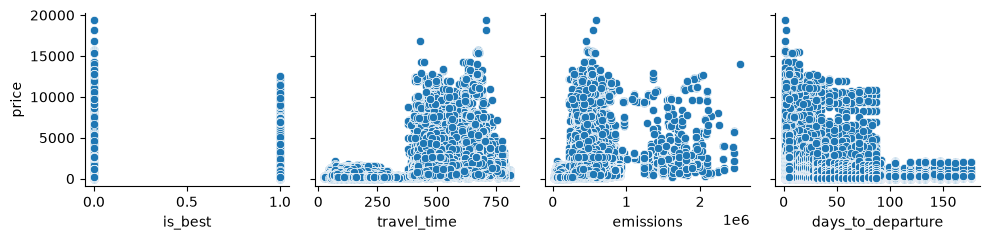

In [7]:
y = 'price'
features = data.drop(columns=[y]).select_dtypes(include="number").columns.to_list()
print(features)
sns.pairplot(data, x_vars=features, y_vars=[y])
plt.tight_layout()

In [9]:
data.to_parquet("cleaned_flights_for_modelling.parquet", index=False, compression="zstd")